# Mission 5 · Grad-CAM 해석, 위험도 기준, 결과 데이터 정의 (최종 모델 R50)

최종 모델 R50(ResNet50, 여백 크롭, 5-fold)의 체크포인트로 분석한다. 학습은 하지 않는다.

* train 이미지는 그 이미지가 검증에 쓰인 fold의 모델로 해석한다. 모델이 학습 중 본 이미지를 해석하지 않기 위해서다.
* 위험도 경계는 OOF 예측으로만 정한다. test 결과로 정하지 않는다.
* test 이미지는 5개 fold 모델로 예측하고, 결과 데이터(확률, 라벨, 위험도, Grad-CAM 이미지)를 저장한다.

## 1. 환경 설정과 데이터 로드

전처리는 최종 모델과 같다(여백 크롭 T=10 후 letterbox 224, ImageNet 정규화).

In [1]:
import os, json, time, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix
from scipy.stats import mannwhitneyu
from matplotlib import font_manager
for _f in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if _f in {f.name for f in font_manager.fontManager.ttflist}: plt.rcParams["font.family"] = _f; break
plt.rcParams["axes.unicode_minus"] = False

D = next(p for p in ["../../data"] if os.path.exists(os.path.join(p, "train.csv")))
OUT = "../../analysis/m5"; CAM_DIR = f"{OUT}/gradcam_test"; os.makedirs(CAM_DIR, exist_ok=True)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
MODEL_VERSION = "R50_resnet50_crop_letterbox_5fold"
CKPT = "../../outputs/resnet50_R50F5_fold{}.pt"
CLASSES = ["NORMAL", "PNEUMONIA"]

def crop_content(img, T=10):
    a = np.asarray(img.convert("L")); r, c = np.where(a > T)
    return img if len(r) == 0 else img.crop((c.min(), r.min(), c.max() + 1, r.max() + 1))
def letterbox(img, size=224):
    img = img.convert("L"); w, h = img.size; s = size / max(w, h)
    nw, nh = max(1, round(w * s)), max(1, round(h * s))
    c = Image.new("L", (size, size), 0); c.paste(img.resize((nw, nh), Image.BILINEAR), ((size - nw) // 2, (size - nh) // 2)); return c
eval_tf = transforms.Compose([transforms.Grayscale(num_output_channels=3), transforms.ToTensor(),
                              transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

tr = pd.read_csv(os.path.join(D, "train.csv")); te = pd.read_csv(os.path.join(D, "test.csv"))
y = tr.label.astype(int).values
splits = list(StratifiedKFold(5, shuffle=True, random_state=42).split(np.zeros(len(y)), y))
fold_of = np.empty(len(y), int)
for k, (_, va) in enumerate(splits): fold_of[va] = k
oof = np.load("../../outputs/oof_R50.npy")
def load_train(i): return letterbox(crop_content(Image.open(os.path.join(D, "train", tr.file_name[i]))))
test_imgs = [letterbox(crop_content(Image.open(os.path.join(D, "test", f)))) for f in te.file_name]   # [결과 데이터] 원본 이미지 → 모델 입력 전처리
print("device:", device, "| train", len(tr), "| test", len(te))

device: mps | train 5216 | test 624


## 2. 모델 로드와 Grad-CAM

Grad-CAM은 마지막 합성곱 블록(`layer4`)의 특징 맵에, 판정한 클래스 점수의 기울기를 곱해 중요 영역을 계산한다. 값이 큰 곳이 판정에 크게 기여한 영역이다. 각 이미지는 모델이 판정한 클래스 기준으로 계산한다.

In [2]:
def load_model(k):
    m = models.resnet50(weights=None)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, 2))
    m.load_state_dict(torch.load(CKPT.format(k), map_location="cpu")); return m.to(device).eval()
MODELS = [load_model(k) for k in range(5)]

class GradCAM:
    def __init__(self, model):
        self.model, self.acts, self.grads = model, None, None
        model.layer4.register_forward_hook(self._hook)
    def _hook(self, module, inp, out):
        self.acts = out
        if out.requires_grad:   # 예측(no_grad) 단계에서는 훅을 걸지 않는다
            out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x, cls):
        self.model.zero_grad(); logits = self.model(x); logits[0, cls].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min(); return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()
CAMS = [GradCAM(m) for m in MODELS]

def cam_for(img, k, cls):
    x = eval_tf(img).unsqueeze(0).to(device)
    with torch.enable_grad(): return CAMS[k](x, cls)
print("models loaded:", len(MODELS))

models loaded: 5


## 3. 해석 1 · 잘 맞힌 이미지

확신이 높은 정상(TN)과 폐렴(TP) 각 4장이다. 모델이 폐 영역을 보고 판단하는지 확인한다. 위 줄은 원본, 아래 줄은 Grad-CAM 겹친 이미지이다.

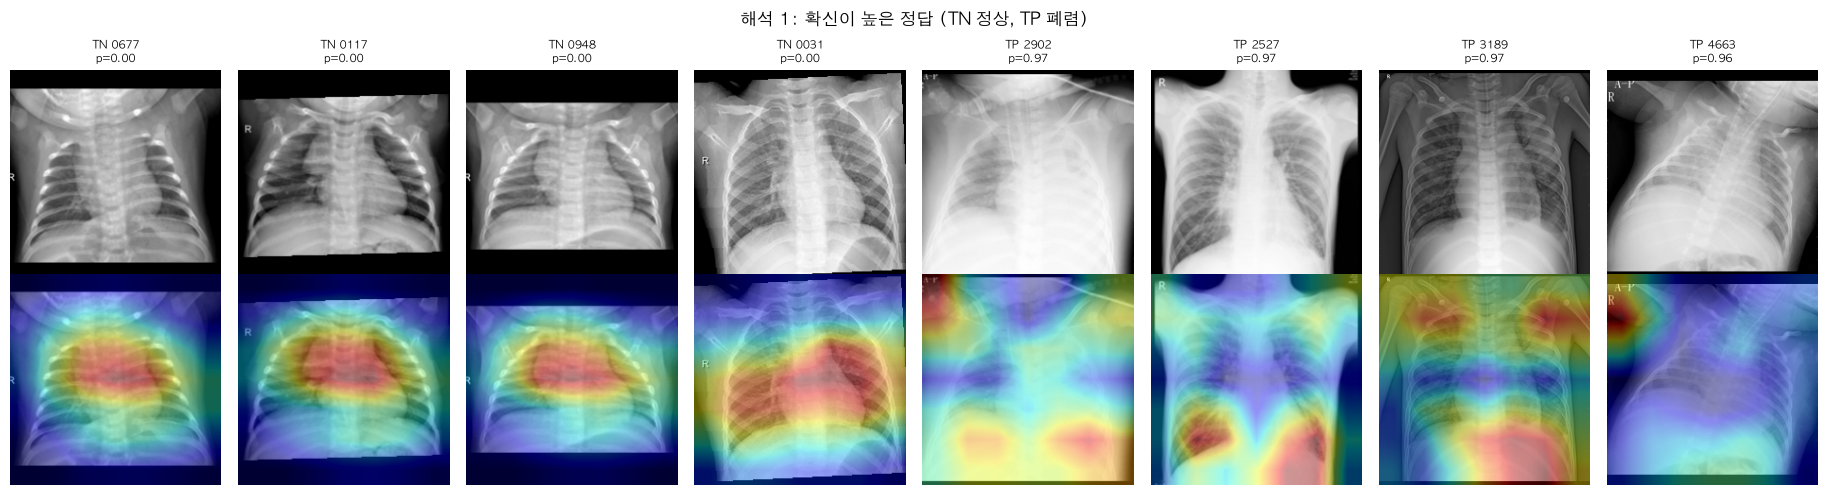

In [3]:
pred = (oof >= 0.5).astype(int)
tp = np.where((y == 1) & (pred == 1))[0]; tn = np.where((y == 0) & (pred == 0))[0]
fn = np.where((y == 1) & (pred == 0))[0]; fp = np.where((y == 0) & (pred == 1))[0]
def show(groups, title, path):
    items = [(g, i) for g, idx in groups for i in idx]
    fig, axes = plt.subplots(2, len(items), figsize=(2.3 * len(items), 5))
    for c, (g, i) in enumerate(items):
        img = load_train(i); cls = int(oof[i] >= 0.5); cam = cam_for(img, fold_of[i], cls)
        axes[0, c].imshow(img, cmap="gray"); axes[0, c].axis("off")
        axes[0, c].set_title(f"{g} {tr.file_name[i][6:10]}\np={oof[i]:.2f}", fontsize=8)
        axes[1, c].imshow(img, cmap="gray"); axes[1, c].imshow(cam, cmap="jet", alpha=0.4); axes[1, c].axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.savefig(path, dpi=100); plt.show()
show([("TN", tn[np.argsort(oof[tn])][:4]), ("TP", tp[np.argsort(-oof[tp])][:4])],
     "해석 1: 확신이 높은 정답 (TN 정상, TP 폐렴)", f"{OUT}/gradcam_correct.png")

## 4. 해석 2 · 틀린 이미지

Mission 4에서 확인한 두 가지 오류를 본다. 확신을 갖고 놓친 폐렴(FN) 4장과 확신을 갖고 폐렴으로 잘못 본 정상(FP) 4장이다. 모델이 폐가 아닌 곳(어깨, 목, 표시 문자, 장치, 검은 여백)을 보고 판단했는지 확인한다.

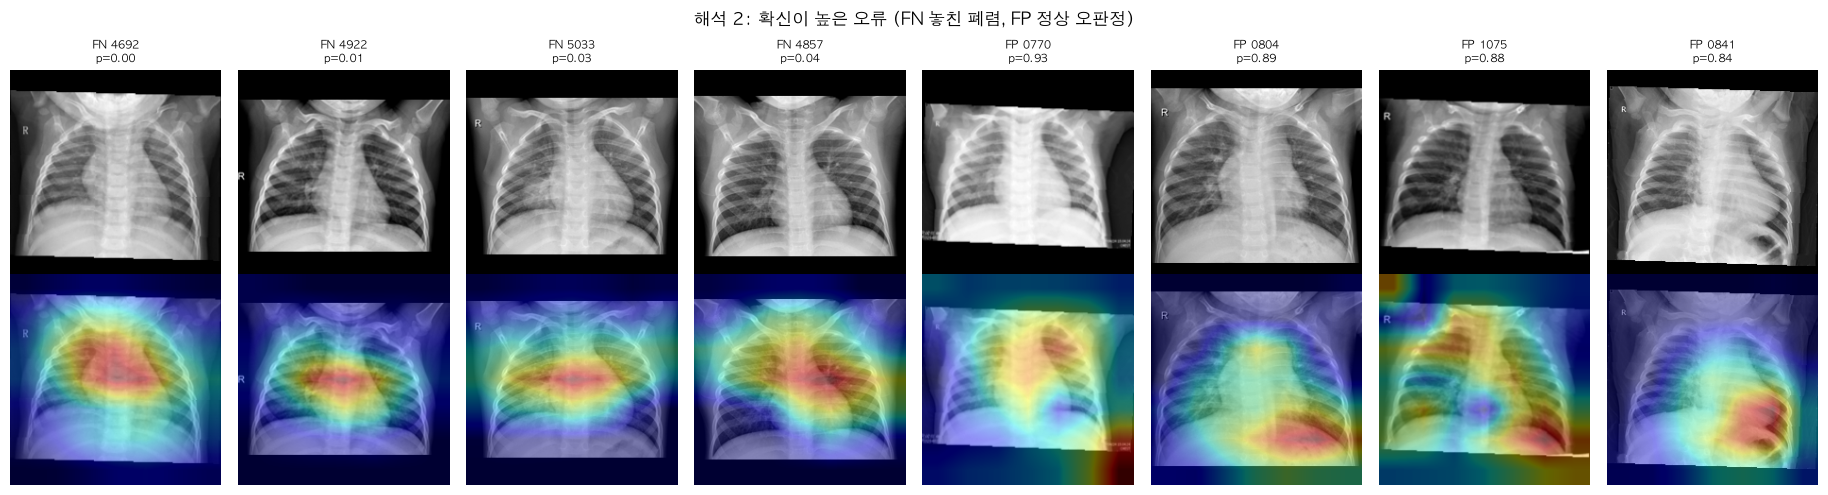

In [4]:
show([("FN", fn[np.argsort(oof[fn])][:4]), ("FP", fp[np.argsort(-oof[fp])][:4])],
     "해석 2: 확신이 높은 오류 (FN 놓친 폐렴, FP 정상 오판정)", f"{OUT}/gradcam_errors.png")

## 5. 해석 3 · 주목 영역의 수치 비교

폐 영역 마스크가 없으므로 근사 영역으로 비교한다.

* **흉곽 중앙 비율**: 크롭된 내용 영역의 가로 15~85%, 세로 15~80% 사각형 안에 들어간 Grad-CAM 값의 비율. 폐가 주로 있는 곳이다.
* **여백 비율**: 검은 여백(밝기 10 이하) 위에 놓인 Grad-CAM 값의 비율. 진단과 관계없는 곳이다.

맞힌 이미지 표본(정상·폐렴 각 60장)과 모든 오류 이미지를 비교한다.

In [5]:
def attention_stats(i):
    img = load_train(i); a = np.asarray(img); cls = int(oof[i] >= 0.5); cam = cam_for(img, fold_of[i], cls)
    m = a > 10; r, c = np.where(m); r0, r1, c0, c1 = r.min(), r.max(), c.min(), c.max()
    hh, ww = r1 - r0, c1 - c0
    box = np.zeros_like(m); box[r0 + int(0.15 * hh): r0 + int(0.80 * hh), c0 + int(0.15 * ww): c0 + int(0.85 * ww)] = True
    tot = cam.sum() + 1e-8
    return dict(흉곽중앙비율=float(cam[box].sum() / tot), 여백비율=float(cam[~m].sum() / tot))
rng = np.random.default_rng(0)
groups = {"정상 맞힘(TN)": rng.choice(tn, 60, replace=False), "폐렴 맞힘(TP)": rng.choice(tp, 60, replace=False),
          "놓친 폐렴(FN)": fn, "정상 오판정(FP)": fp}
A = {g: pd.DataFrame([attention_stats(i) for i in idx]) for g, idx in groups.items()}
att = pd.DataFrame({g: d.median() for g, d in A.items()}).T.round(3); att["장수"] = [len(v) for v in groups.values()]
print(att.to_string())
for a, b in [("놓친 폐렴(FN)", "폐렴 맞힘(TP)"), ("정상 오판정(FP)", "정상 맞힘(TN)")]:
    print(f"{a} vs {b} (Mann-Whitney p):", {c: round(float(mannwhitneyu(A[a][c], A[b][c]).pvalue), 4) for c in A[a].columns})
att.to_csv(f"{OUT}/attention_stats.csv", encoding="utf-8-sig")

            흉곽중앙비율   여백비율  장수
정상 맞힘(TN)    0.648  0.079  60
폐렴 맞힘(TP)    0.230  0.339  60
놓친 폐렴(FN)    0.739  0.048  46
정상 오판정(FP)   0.482  0.244  19
놓친 폐렴(FN) vs 폐렴 맞힘(TP) (Mann-Whitney p): {'흉곽중앙비율': 0.0, '여백비율': 0.0}
정상 오판정(FP) vs 정상 맞힘(TN) (Mann-Whitney p): {'흉곽중앙비율': 0.0, '여백비율': 0.0}


## 6. 위험도(Risk Level) 기준

폐렴을 놓치지 않는 것(민감도)을 우선해 세 단계로 나눈다. 경계는 OOF 예측으로만 정한다. 각 구간 안의 오류율을 기준으로 한다.

* **Low**: Low로 판정된 이미지 중 실제 폐렴이 1% 이하가 되는 가장 큰 확률값을 경계로 쓴다. 정상일 가능성이 높다.
* **High**: High로 판정된 이미지 중 실제 정상이 0.5% 이하가 되는 가장 작은 확률값을 경계로 쓴다. 폐렴일 가능성이 높다.
* **Medium**: 그 사이. 판단이 애매하므로 전문의 재확인 대상이다.

처음에는 "Low에서 놓치는 폐렴이 전체 폐렴의 1% 이하"로 정했으나, 폐렴이 3,875장이라 38장까지 허용되어 Low 경계가 0.43까지 올라가고 Medium이 8장뿐이었다. 그래서 구간 안의 오류율 기준으로 바꿨다.

In [6]:
grid = np.round(np.arange(0.01, 1.0, 0.01), 2)
low_cut = max(t for t in grid if (oof < t).sum() > 0 and y[oof < t].mean() <= 0.01)        # Low 구간 안의 실제 폐렴 비율 ≤ 1%
high_cut = min(t for t in grid if (oof >= t).sum() > 0 and y[oof >= t].mean() >= 0.995)  # High 구간 안의 실제 정상 비율 ≤ 0.5%
def risk_level(p):   # [결과 데이터] 위험도 생성 위치
    return np.where(p < low_cut, "Low", np.where(p < high_cut, "Medium", "High"))
lv = risk_level(oof)
risk_tab = pd.DataFrame({"level": lv, "truth": y}).groupby("level").agg(장수=("truth", "size"), 실제폐렴비율=("truth", "mean")).reindex(["Low", "Medium", "High"])
print(f"Low 경계 {low_cut}, High 경계 {high_cut}")
print(risk_tab.round(4).to_string())
print("Low에 들어간 실제 폐렴:", int(((lv == "Low") & (y == 1)).sum()), "장 | High에 들어간 실제 정상:", int(((lv == "High") & (y == 0)).sum()), "장")
risk_tab.round(4).to_csv(f"{OUT}/risk_levels_oof.csv", encoding="utf-8-sig")

Low 경계 0.1, High 경계 0.49
          장수  실제폐렴비율
level               
Low     1289  0.0093
Medium    77  0.4156
High    3850  0.9951
Low에 들어간 실제 폐렴: 12 장 | High에 들어간 실제 정상: 19 장


## 7. test 결과 데이터 생성과 저장

서비스에서 저장할 데이터를 test 624장에 대해 만든다. 각 값이 만들어지는 위치는 코드 주석(`[결과 데이터]`)으로 표시했다.

| 항목 | 의미 | 생성 위치 |
|---|---|---|
| file_name | 원본 이미지 식별자 | `test.csv` 로드 |
| prob_pneumonia | 5-fold 평균 폐렴 확률 (약한 TTA 포함) | `predict_proba` 평균 |
| pred_label, pred_name | 예측 라벨 (0 NORMAL, 1 PNEUMONIA) | 확률 ≥ 0.5 |
| risk_level | 위험도 (Low / Medium / High) | `risk_level(prob)` |
| gradcam_path | 판정 근거 이미지 경로 | 5개 fold 모델 Grad-CAM 평균 |
| model_version | 예측에 쓴 모델 버전 | `MODEL_VERSION` |

In [7]:
@torch.no_grad()
def predict_proba(m, imgs):
    out = []
    for x in DataLoader([eval_tf(im) for im in imgs], batch_size=32):
        x = x.to(device); p = F.softmax(m(x), 1)
        s = x.shape[-1]; c = int(s * 0.06)
        xz = F.interpolate(x[..., c:s - c, c:s - c], size=(s, s), mode="bilinear", align_corners=False)
        out.append(((p + F.softmax(m(xz), 1)) / 2)[:, 1].cpu())
    return torch.cat(out).numpy()

prob = np.mean([predict_proba(m, test_imgs) for m in MODELS], axis=0)   # [결과 데이터] 예측 확률 생성 위치
label = (prob >= 0.5).astype(int)                                       # [결과 데이터] 예측 라벨 생성 위치
sub = pd.read_csv("../../outputs/submission_resnet50_R50F5_f01234.csv")
print("제출 파일과 라벨 일치율:", round(float((sub.label.values == label).mean()), 4))

t0 = time.time(); paths = []
for i, img in enumerate(test_imgs):                                     # [결과 데이터] Grad-CAM 이미지 생성 위치
    cam = np.mean([cam_for(img, k, int(label[i])) for k in range(5)], axis=0)
    heat = (plt.cm.jet(cam)[..., :3] * 255).astype(np.uint8)
    base = np.stack([np.asarray(img)] * 3, -1).astype(np.float32)
    over = (0.6 * base + 0.4 * heat).clip(0, 255).astype(np.uint8)
    path = f"{CAM_DIR}/{te.file_name[i].replace('.png', '')}_gradcam.png"
    Image.fromarray(over).save(path); paths.append(os.path.relpath(path, "../.."))   # 결과 파일에는 프로젝트과정 기준 경로로 기록
print(f"Grad-CAM 이미지 {len(paths)}장 저장 ({time.time() - t0:.0f}초)")

results = pd.DataFrame({"file_name": te.file_name, "prob_pneumonia": prob.round(4), "pred_label": label,
                        "pred_name": [CLASSES[v] for v in label], "risk_level": risk_level(prob),
                        "gradcam_path": paths, "model_version": MODEL_VERSION})
results.to_csv(f"{OUT}/test_results_R50.csv", index=False, encoding="utf-8-sig")
print(results.head().to_string())
print("\ntest 위험도 분포:", results.risk_level.value_counts().reindex(["Low", "Medium", "High"]).to_dict())
json.dump({"low_cut": float(low_cut), "high_cut": float(high_cut), "model_version": MODEL_VERSION,
           "risk_oof": risk_tab.round(4).reset_index().to_dict(orient="records"),
           "attention_median": att.reset_index().to_dict(orient="records"),
           "test_risk_counts": results.risk_level.value_counts().to_dict()},
          open(f"{OUT}/summary.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)

제출 파일과 라벨 일치율: 1.0


Grad-CAM 이미지 624장 저장 (109초)
       file_name  prob_pneumonia  pred_label  pred_name risk_level                                    gradcam_path                      model_version
0  test_0001.png          0.1771           0     NORMAL     Medium  analysis/m5/gradcam_test/test_0001_gradcam.png  R50_resnet50_crop_letterbox_5fold
1  test_0002.png          0.7493           1  PNEUMONIA       High  analysis/m5/gradcam_test/test_0002_gradcam.png  R50_resnet50_crop_letterbox_5fold
2  test_0003.png          0.9288           1  PNEUMONIA       High  analysis/m5/gradcam_test/test_0003_gradcam.png  R50_resnet50_crop_letterbox_5fold
3  test_0004.png          0.9257           1  PNEUMONIA       High  analysis/m5/gradcam_test/test_0004_gradcam.png  R50_resnet50_crop_letterbox_5fold
4  test_0005.png          0.9366           1  PNEUMONIA       High  analysis/m5/gradcam_test/test_0005_gradcam.png  R50_resnet50_crop_letterbox_5fold

test 위험도 분포: {'Low': 110, 'Medium': 50, 'High': 464}


# 💡 Reflection Questions
- **Grad-CAM은 무엇이며 왜 필요한가?**
    - 합성곱 신경망이 어느 영역을 보고 판단했는지 히트맵으로 보여 주는 방법이다. 정확도만으로는 모델이 올바른 근거로 판단하는지 알 수 없다. 이번 분석에서도 정확도는 높았지만 Grad-CAM으로 폐 바깥의 단서에 의존하는 경향을 발견했다.
- **모델이 실제로 중요한 영역을 보고 판단하는가?**
    - 정상 판단은 흉곽 중앙을 보지만, 폐렴 판단은 폐보다 어깨, 촬영 표시, 배, 가장자리를 보는 경우가 많다. 폐렴을 맞힌 이미지에서 Grad-CAM 값의 34%가 검은 여백 위에 있었다. 중요한 영역만 보고 판단한다고 보기 어렵다.
- **모델의 판단 근거를 신뢰할 수 있는가?**
    - 그대로 신뢰하기 어렵다. 지름길 단서로 맞힌 경우가 섞여 있어서, 촬영 장비나 병원이 바뀌면 성능이 떨어질 수 있다. 실제로 검증 0.99와 리더보드 0.88의 차이가 있었다.
- **모델의 한계와 서비스 적용 시 문제는?**
    - 소아 영상으로만 학습해 성인에게는 쓸 수 없다. 촬영 조건이 다른 병원에서는 성능이 떨어질 수 있다. 선명하게 찍힌 폐렴을 확신을 갖고 놓치는 경우가 있다. 위험도 경계도 운영 데이터로 다시 맞춰야 한다.
- **추가로 개선한다면?**
    - 폐 영역 분할 마스크로 폐 바깥을 가리고 학습해 지름길 단서를 줄인다. 다른 병원 데이터로 외부 검증을 한다(대회 규칙 밖에서). Grad-CAM이 폐 바깥에 집중하는 이미지를 자동으로 표시해 전문의가 확인하게 한다.
- **모델 결과를 왜 DB에 저장해야 하는가?**
    - 어떤 영상에 어떤 판단을 했는지 나중에 확인하고 책임을 추적할 수 있어야 한다. 의료진이 판독한 정답과 비교해 성능을 계속 점검하고, 모델 버전별로 결과를 비교할 수 있다.
- **저장된 데이터는 어떻게 활용할 수 있는가?**
    - 위험도에 따라 판독 순서를 정하고, Grad-CAM 이미지를 판독 화면에 함께 보여 준다. 전문의 판독 결과가 쌓이면 오류 사례를 모아 재학습하거나, 경계를 다시 정하는 데 쓴다.
- **의료 서비스에서 설명 가능한 AI가 왜 중요한가?**
    - 의료 판단은 환자에게 직접 영향을 주므로, 결과만이 아니라 근거를 의료진이 확인할 수 있어야 한다. 이번처럼 모델이 잘못된 단서에 의존하는 문제도 설명을 봐야 찾을 수 있다.
- **현재 모델을 서비스에 적용할 때 생길 수 있는 문제는?**
    - 지름길 단서 의존 때문에 다른 병원 영상에서 오판이 늘 수 있다. 확신을 갖고 놓친 폐렴이 Low로 분류되어 판독이 늦어질 수 있다. 성인 영상이 들어오면 잘못된 판단을 할 수 있으므로 입력 단계에서 걸러야 한다.

# Risk Level

**위험도 구분 결과**

예측 확률(5-fold 평균 폐렴 확률)을 두 경계로 나눠 세 단계로 구분한다. 이 위험도는 판독 순서에 대한 연구용 제안이며 임상 지침이 아니다. 실제로 쓰려면 외부 데이터 검증과 의료진 확인이 먼저 필요하다.

| 위험도 | 폐렴 확률 | 경계 기준 (OOF) | OOF 장수 | 실제 폐렴 비율 (OOF 추정) | 제안 우선순위 (연구용) |
|---|---|---|---|---|---|
| Low | 0.10 미만 | 구간 안의 실제 폐렴 ≤ 1% | 1,289 | 0.9% (12장) | 일반 판독 순서 (판독 생략 아님) |
| Medium | 0.10 이상 0.49 미만 | 그 사이 | 77 | 41.6% | 우선 재확인 권고 |
| High | 0.49 이상 | 구간 안의 실제 정상 ≤ 0.5% | 3,850 | 99.5% | 최우선 판독 권고 |

**Threshold 설정 근거**
* 경계는 train의 OOF 예측으로만 정했다. test 결과는 쓰지 않았다.
* 경계를 "전체 대비 비율"이 아니라 "구간 안의 오류율"로 정했다. 의료진이 보는 것은 "Low라고 표시된 영상 중 몇 %가 실제 폐렴인가"이기 때문이다.
* 판정 라벨의 임계값(0.5)과 위험도 경계는 역할이 다르다. 라벨은 정상과 폐렴을 나누고, 위험도는 판독 순서를 정한다.

**실제 의료 서비스 기준 설계: Sensitivity 우선**
* 서비스 상황: 이 모델은 진단을 대신하지 않고, 판독 대기 영상의 순서를 정하는 분류(triage) 도구로 쓴다고 가정한다. 모든 영상은 결국 전문의가 판독한다.
* 민감도를 우선한 이유: 폐렴을 정상으로 놓치면(FN) 치료가 늦어지고, 소아는 빠르게 나빠질 수 있다. 정상을 폐렴으로 보면(FP) 재확인과 추가 검사 비용이 생기지만 되돌릴 수 있다. 두 오류의 피해가 다르므로 FN을 줄이는 쪽을 택했다.
* 기준에 반영한 방식: Low 경계를 0.10으로 낮게 두어, 실제 폐렴 3,875장 중 99.7%(3,863장)가 Medium 이상으로 분류되어 우선 판독 대상이 된다. 애매한 구간은 Medium으로 따로 두어 전문의가 먼저 확인하게 했다.
* 감수한 비용: 실제 정상 1,341장 중 64장(4.8%)이 Medium 이상에 들어가 재확인 업무가 생긴다.
* Specificity 우선이었다면: Low 경계를 높여 정상을 더 많이 Low로 보내 의료진 부담을 줄일 수 있다. 하지만 처음 기준(Low 경계 0.43)에서는 폐렴 38장이 Low에 들어갔다. 선별 목적의 서비스에서는 받아들이기 어렵다.

**기준이 잘못 설정될 경우의 문제**
* Low 경계가 너무 높으면: 폐렴 환자가 Low로 분류되어 판독이 늦어진다. 처음 기준에서는 38장이 Low에 들어갔다.
* High 경계가 너무 낮으면: 정상이 High로 분류되어 불필요한 검사, 항생제 처방, 보호자 불안이 늘어난다.
* Medium이 너무 넓으면: 재확인 대상이 많아져 의료진이 경고에 무뎌지고(alarm fatigue), 모델을 쓰는 의미가 줄어든다. 너무 좁으면(처음 기준의 8장) 재확인 단계가 사실상 없어진다.
* 학습 데이터와 운영 데이터의 분포가 다르면: 이 경계는 train 분포에서 정한 것이다. 리더보드 기반 사후 분석에서 test는 폐렴 판정을 늘리면 오히려 틀리는 경향을 보였으므로, 실제 운영에서는 정상이 High로 몰릴 수 있다. 운영 데이터로 경계를 다시 확인해야 한다.
* Low를 "판독 생략"으로 쓰면: 확신을 갖고 놓친 폐렴 12장이 여전히 Low에 있다. Low는 판독 순서를 뒤로 미루는 단계일 뿐, 판독을 생략하는 단계로 쓰면 안 된다.